In [5]:

import pandas as pd
import numpy as np

df = pd.read_csv(
    r"C:\Users\PRAJAKTA\Desktop\imarticus\WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0


In [7]:
# Check the data type
print("Before cleaning:", df["TotalCharges"].dtype)

# Find values that contain only spaces or are empty
blank_values = df["TotalCharges"].astype(str).str.strip().eq("")

print("Blank TotalCharges values:", blank_values.sum())

# Display examples of blank values, if any
print(df.loc[blank_values, ["customerID", "tenure", "TotalCharges"]].head())

Before cleaning: object
Blank TotalCharges values: 11
      customerID  tenure TotalCharges
488   4472-LVYGI       0             
753   3115-CZMZD       0             
936   5709-LVOEQ       0             
1082  4367-NUYAO       0             
1340  1371-DWPAZ       0             


In [8]:
import pandas as pd

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

# Verify the conversion
print("New data type:", df["TotalCharges"].dtype)

print("Missing TotalCharges values:", df["TotalCharges"].isnull().sum())

# Display the affected records
print(df.loc[
    df["TotalCharges"].isnull(),
    ["customerID", "tenure", "TotalCharges"]
])

New data type: float64
Missing TotalCharges values: 11
      customerID  tenure  TotalCharges
488   4472-LVYGI       0           NaN
753   3115-CZMZD       0           NaN
936   5709-LVOEQ       0           NaN
1082  4367-NUYAO       0           NaN
1340  1371-DWPAZ       0           NaN
3331  7644-OMVMY       0           NaN
3826  3213-VVOLG       0           NaN
4380  2520-SGTTA       0           NaN
5218  2923-ARZLG       0           NaN
6670  4075-WKNIU       0           NaN
6754  2775-SEFEE       0           NaN


In [9]:
# Count customers who left and stayed
churn_counts = df["Churn"].value_counts()

print("Customer churn counts:")
print(churn_counts)

# Calculate percentages
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

print("\nCustomer churn percentages:")
print(churn_percentages.round(2))

# Calculate overall churn rate
churn_rate = (df["Churn"] == "Yes").mean() * 100

print(f"\nOverall customer churn rate: {churn_rate:.2f}%")

Customer churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Overall customer churn rate: 26.54%


In [10]:
# Count customers by contract type and churn status
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

print("Customer counts by contract type:")
print(contract_churn)

# Calculate churn rate for each contract type
contract_churn_rate = (
    pd.crosstab(df["Contract"], df["Churn"], normalize="index")["Yes"]
    * 100
)

print("\nChurn rate by contract type:")
print(contract_churn_rate.round(2))

Customer counts by contract type:
Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48

Churn rate by contract type:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Yes, dtype: float64


In [11]:
# Create tenure groups
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months",
            "25-48 months", "49-72 months"]
)

# Calculate churn rate for each tenure group
tenure_churn = (
    df.groupby("TenureGroup", observed=False)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

print("Churn rate by customer tenure:")
print(tenure_churn.round(2))

Churn rate by customer tenure:
TenureGroup
0-12 months     47.44
13-24 months    28.71
25-48 months    20.39
49-72 months     9.51
Name: Churn, dtype: float64


In [12]:
# Count customers by payment method and churn
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"]
)

print("Customer counts by payment method:")
print(payment_churn)

# Calculate churn rate for each payment method
payment_churn_rate = (
    pd.crosstab(
        df["PaymentMethod"],
        df["Churn"],
        normalize="index"
    )["Yes"] * 100
)

print("\nChurn rate by payment method:")
print(payment_churn_rate.round(2).sort_values(ascending=False))

Customer counts by payment method:
Churn                        No   Yes
PaymentMethod                        
Bank transfer (automatic)  1286   258
Credit card (automatic)    1290   232
Electronic check           1294  1071
Mailed check               1304   308

Churn rate by payment method:
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Yes, dtype: float64


In [13]:
# Calculate average monthly charges by churn status
monthly_charges_analysis = (
    df.groupby("Churn")["MonthlyCharges"]
      .agg(["mean", "median", "count"])
      .round(2)
)

print("Monthly charges by churn status:")
print(monthly_charges_analysis)

Monthly charges by churn status:
        mean  median  count
Churn                      
No     61.27   64.43   5174
Yes    74.44   79.65   1869


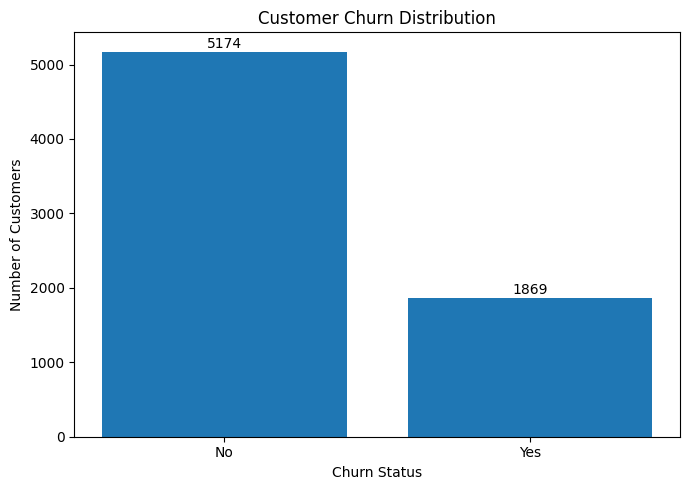

In [14]:
import matplotlib.pyplot as plt

# Count customers who stayed and left
churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"])

# Create bar chart
plt.figure(figsize=(7, 5))
plt.bar(churn_counts.index, churn_counts.values)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

# Display values above the bars
for i, value in enumerate(churn_counts.values):
    plt.text(i, value + 50, str(value), ha="center")

plt.tight_layout()
plt.show()

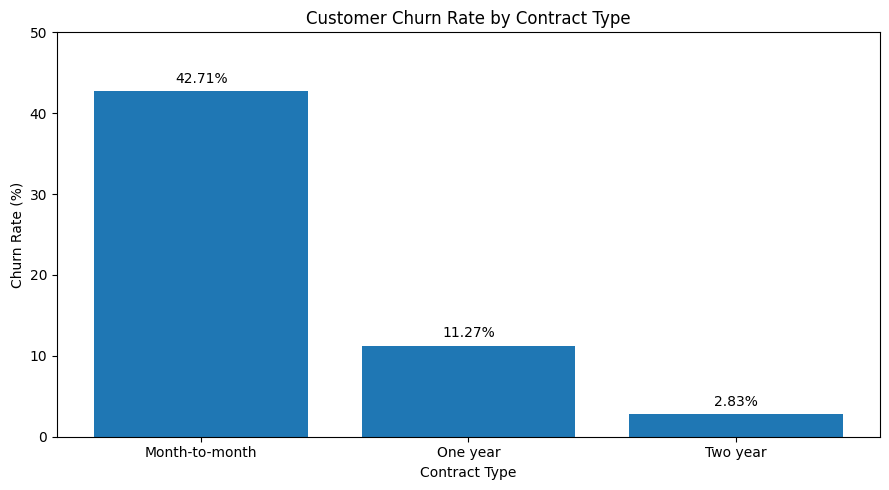

In [15]:
import matplotlib.pyplot as plt
import pandas as pd

# Calculate churn rate by contract type
contract_churn_rate = (
    df.groupby("Contract", observed=False)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .sort_values(ascending=False)
)

# Create the bar chart
plt.figure(figsize=(9, 5))
plt.bar(contract_churn_rate.index, contract_churn_rate.values)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

# Display percentages above bars
for i, value in enumerate(contract_churn_rate.values):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

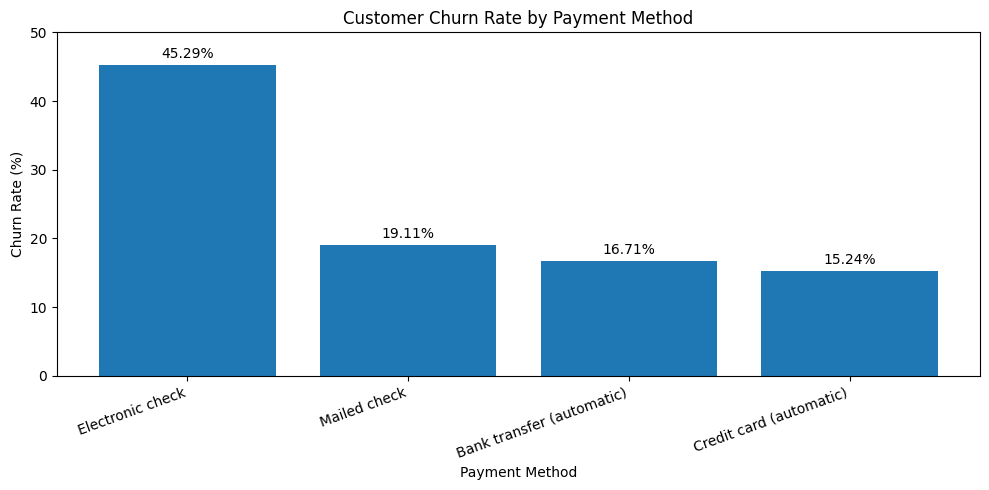

In [16]:
import matplotlib.pyplot as plt

# Calculate churn rate by payment method
payment_churn_rate = (
    df.groupby("PaymentMethod", observed=False)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .sort_values(ascending=False)
)

# Create chart
plt.figure(figsize=(10, 5))
plt.bar(payment_churn_rate.index, payment_churn_rate.values)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 50)

# Add percentage labels
for i, value in enumerate(payment_churn_rate.values):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

Average monthly charges:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


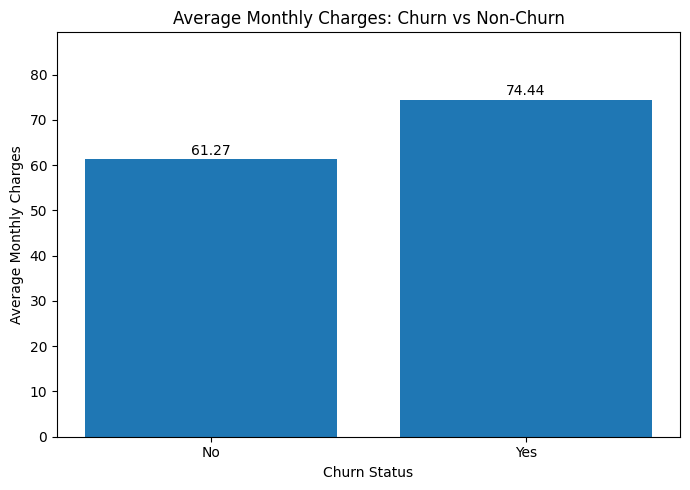

In [17]:
import matplotlib.pyplot as plt

# Calculate average monthly charges
charges = df.groupby("Churn")["MonthlyCharges"].mean()

print("Average monthly charges:")
print(charges.round(2))

# Create bar chart
plt.figure(figsize=(7, 5))
plt.bar(charges.index, charges.values)

plt.title("Average Monthly Charges: Churn vs Non-Churn")
plt.xlabel("Churn Status")
plt.ylabel("Average Monthly Charges")
plt.ylim(0, charges.max() * 1.2)

# Display values above bars
for i, value in enumerate(charges.values):
    plt.text(i, value + 1, f"{value:.2f}", ha="center")

plt.tight_layout()
plt.show()

In [18]:
# Calculate churn rate by internet service
internet_churn_rate = (
    df.groupby("InternetService", observed=False)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .sort_values(ascending=False)
)

print("Churn rate by internet service:")
print(internet_churn_rate.round(2))

Churn rate by internet service:
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64


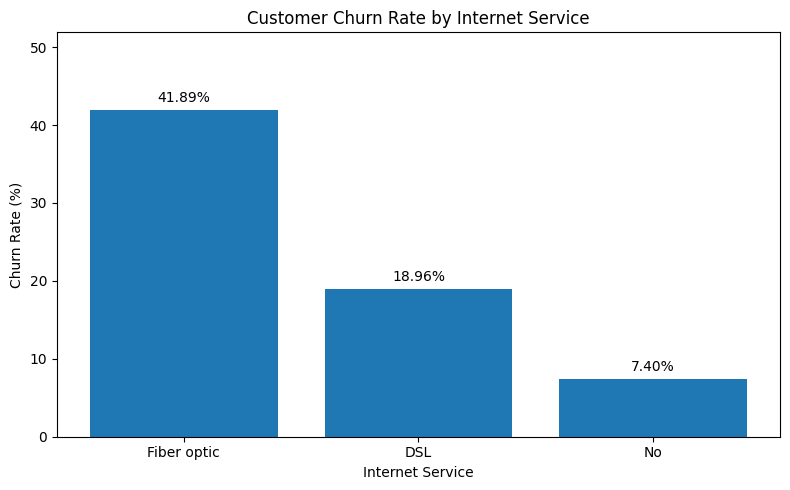

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(internet_churn_rate.index, internet_churn_rate.values)

plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

for i, value in enumerate(internet_churn_rate.values):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.ylim(0, max(internet_churn_rate.values) + 10)
plt.tight_layout()
plt.show()

In [20]:
# Group customers by tenure
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49-72 months"
    ]
)

# Calculate churn rate by tenure group
tenure_churn_rate = (
    df.groupby("TenureGroup", observed=False)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

print("Churn rate by tenure group:")
print(tenure_churn_rate.round(2))

Churn rate by tenure group:
TenureGroup
0-12 months     47.44
13-24 months    28.71
25-48 months    20.39
49-72 months     9.51
Name: Churn, dtype: float64


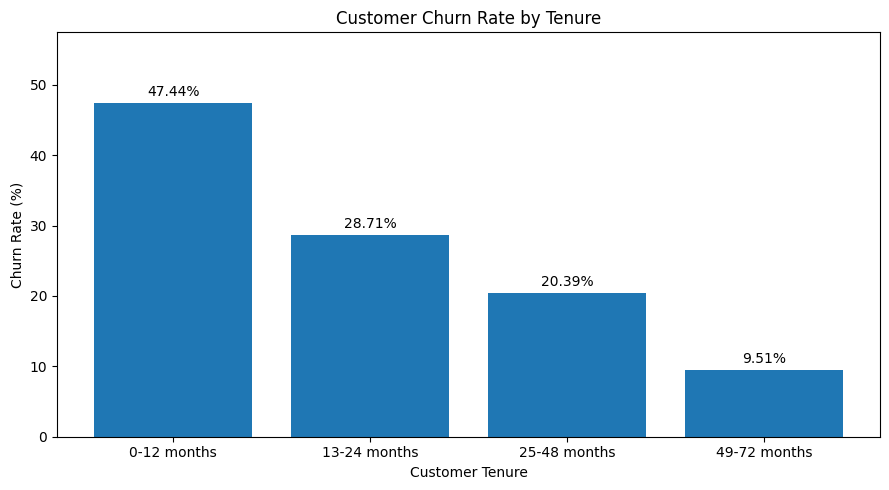

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(tenure_churn_rate.index.astype(str),
        tenure_churn_rate.values)

plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")

for i, value in enumerate(tenure_churn_rate.values):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.ylim(0, max(tenure_churn_rate.values) + 10)
plt.tight_layout()
plt.show()

In [22]:
# Total customers
total_customers = len(df)

# Customers who left
churned_customers = (df["Churn"] == "Yes").sum()

# Overall churn rate
churn_rate = churned_customers / total_customers * 100

# Average tenure
avg_tenure = df["tenure"].mean()

# Average monthly charges
avg_monthly_charges = df["MonthlyCharges"].mean()

# Average total charges, excluding missing values
avg_total_charges = df["TotalCharges"].mean()

print("TELCO CUSTOMER CHURN - KEY METRICS")
print("----------------------------------")
print("Total customers:", total_customers)
print("Customers churned:", churned_customers)
print(f"Overall churn rate: {churn_rate:.2f}%")
print(f"Average tenure: {avg_tenure:.2f} months")
print(f"Average monthly charges: {avg_monthly_charges:.2f}")
print(f"Average total charges: {avg_total_charges:.2f}")

TELCO CUSTOMER CHURN - KEY METRICS
----------------------------------
Total customers: 7043
Customers churned: 1869
Overall churn rate: 26.54%
Average tenure: 32.37 months
Average monthly charges: 64.76
Average total charges: 2283.30


In [6]:
# Save the cleaned dataset
output_path = r"C:\Users\PRAJAKTA\Desktop\imarticus\telco_churn_cleaned.csv"

df.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", output_path)

Cleaned dataset saved successfully!
File location: C:\Users\PRAJAKTA\Desktop\imarticus\telco_churn_cleaned.csv


In [7]:
import os
import pandas as pd

print("File exists:", os.path.exists(output_path))

# Read the exported file back
df_check = pd.read_csv(output_path)

print("Saved dataset shape:", df_check.shape)
print("TotalCharges data type:", df_check["TotalCharges"].dtype)
print("Missing TotalCharges:", df_check["TotalCharges"].isnull().sum())

File exists: True
Saved dataset shape: (7043, 21)
TotalCharges data type: object
Missing TotalCharges: 0


In [8]:
print(df.columns.tolist())

print(
    "Duplicate column names:",
    df.columns[df.columns.duplicated()].tolist()
)

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
Duplicate column names: []


In [10]:
# Clean text columns
text_columns = [
    "customerID", "gender", "Partner", "Dependents",
    "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod",
    "Churn"
]

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

# Convert numeric columns
df["SeniorCitizen"] = pd.to_numeric(df["SeniorCitizen"]).astype("int64")
df["tenure"] = pd.to_numeric(df["tenure"]).astype("int64")
df["MonthlyCharges"] = pd.to_numeric(df["MonthlyCharges"])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Create TenureGroup
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"]
)

print("Dataset shape:", df.shape)
print(df.dtypes)

Dataset shape: (7043, 22)
customerID          string[python]
gender              string[python]
SeniorCitizen                int64
Partner             string[python]
Dependents          string[python]
tenure                       int64
PhoneService        string[python]
MultipleLines       string[python]
InternetService     string[python]
OnlineSecurity      string[python]
OnlineBackup        string[python]
DeviceProtection    string[python]
TechSupport         string[python]
StreamingTV         string[python]
StreamingMovies     string[python]
Contract            string[python]
PaperlessBilling    string[python]
PaymentMethod       string[python]
MonthlyCharges             float64
TotalCharges               float64
Churn               string[python]
TenureGroup               category
dtype: object


In [11]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check duplicate customer IDs
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

# Check unique customer IDs
print("Unique customers:", df["customerID"].nunique())

Missing values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
TenureGroup          0
dtype: int64

Duplicate rows: 0
Duplicate customer IDs: 0
Unique customers: 7043


In [12]:
missing_charges = df[df["TotalCharges"].isna()]

print(missing_charges[
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
])

print("\nTenure values of missing records:")
print(missing_charges["tenure"].value_counts())

      customerID  tenure  MonthlyCharges  TotalCharges
488   4472-LVYGI       0           52.55           NaN
753   3115-CZMZD       0           20.25           NaN
936   5709-LVOEQ       0           80.85           NaN
1082  4367-NUYAO       0           25.75           NaN
1340  1371-DWPAZ       0           56.05           NaN
3331  7644-OMVMY       0           19.85           NaN
3826  3213-VVOLG       0           25.35           NaN
4380  2520-SGTTA       0           20.00           NaN
5218  2923-ARZLG       0           19.70           NaN
6670  4075-WKNIU       0           73.35           NaN
6754  2775-SEFEE       0           61.90           NaN

Tenure values of missing records:
tenure
0    11
Name: count, dtype: int64


In [13]:
# Replace missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0.00)

# Verify missing values
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nTotalCharges data type:")
print(df["TotalCharges"].dtype)

print("\nNumber of zero TotalCharges:")
print((df["TotalCharges"] == 0).sum())

Missing values after cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
TenureGroup         0
dtype: int64

TotalCharges data type:
float64

Number of zero TotalCharges:
11


In [14]:
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("Unique customers:", df["customerID"].nunique())

print("\nFinal data types:")
print(df.dtypes)

Total rows: 7043
Total columns: 22
Missing values: 0
Duplicate rows: 0
Duplicate customer IDs: 0
Unique customers: 7043

Final data types:
customerID          string[python]
gender              string[python]
SeniorCitizen                int64
Partner             string[python]
Dependents          string[python]
tenure                       int64
PhoneService        string[python]
MultipleLines       string[python]
InternetService     string[python]
OnlineSecurity      string[python]
OnlineBackup        string[python]
DeviceProtection    string[python]
TechSupport         string[python]
StreamingTV         string[python]
StreamingMovies     string[python]
Contract            string[python]
PaperlessBilling    string[python]
PaymentMethod       string[python]
MonthlyCharges             float64
TotalCharges               float64
Churn               string[python]
TenureGroup               category
dtype: object


In [15]:
print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... TechSupport  \
0  No phone service             DSL             No  ...          No   
1                No             DSL            Yes  ...          No   
2                No             DSL            Yes  ...          No   
3  No phone service             DSL            Yes  ...         Yes   
4                No     Fiber optic             No  ...          No   

  StreamingTV StreamingMovies        Contract PaperlessBilling  \
0          No             

In [17]:
output_path = r"C:\Users\PRAJAKTA\Desktop\imarticus\telco_churn_mysql_ready.csv"

df.to_csv(output_path, index=False)

print("CSV exported successfully!")
print("File:", output_path)

CSV exported successfully!
File: C:\Users\PRAJAKTA\Desktop\imarticus\telco_churn_mysql_ready.csv


In [18]:
import os

print("File exists:", os.path.exists(output_path))
print("File size:", os.path.getsize(output_path), "bytes")

File exists: True
File size: 1068340 bytes
